# Maintenance prédictive des disques durs — Modèle CNN-1D
 · Dataset : Backblaze ST4000DM000 (2016–2022), version prétraitée 

## 1. Configuration

In [1]:
import os
from types import SimpleNamespace

C = SimpleNamespace(
    # Données
    REPO_ID   = "IlyasFardaouixx/backblaze-st4000dm000-predictive-maintenance",
    FILE_NAME = "preprocessed_ST4000DM000.parquet",   # seul fichier utile (RUL + split + normalisation)
    PARQUET_PATH = os.environ.get("PDM_PARQUET"),     # chemin local éventuel, sinon téléchargement HF
    OUT_DIR = "/kaggle/working/cnn1d_outputs" if os.path.isdir("/kaggle/working") else "./cnn1d_outputs",

    # Problème
    WINDOW        = 30,    # longueur de la fenêtre glissante (jours)
    RUL_CAP       = 125,   # plafond de RUL du dataset
    ALERT_HORIZON = 30,    # « panne imminente » = RUL réelle <= 30 jours
    MAX_GAP_DAYS  = 7,     # V2 : trous de dates tolérés (protocole commun)

    # Déséquilibre : nb de fenêtres saines (RUL = 125) par fenêtre en dégradation
    HEALTHY_RATIO     = 2,
    VAL_HEALTHY_RATIO = 2,

    # Entraînement
    BATCH_SIZE   = 1024,
    EPOCHS       = 30,
    LR           = 1e-3,
    WEIGHT_DECAY = 1e-4,
    PATIENCE     = 5,
    MAX_TRAIN_MINUTES = 150,   # garde-fou : arrêt propre avant d'épuiser le quota GPU
    DROPOUT      = 0.3,
    CHANNELS     = (64, 64, 128),
    KERNEL       = 3,

    # Mémoire
    STORE_DTYPE = "float16",   # données min-max dans [0,1] : float16 suffit et divise la RAM par 2
    EVAL_BATCH  = 16384,
    SEED = 42,
)
os.makedirs(C.OUT_DIR, exist_ok=True)

## 2. Imports et environnement

In [2]:
import gc, json, time, math, random
import numpy as np
import polars as pl
import pyarrow.parquet as pq
import psutil
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_recall_curve, average_precision_score,
                             confusion_matrix, precision_score, recall_score, f1_score)

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(C.SEED)

def ram(msg=""):
    v = psutil.virtual_memory()
    rss = psutil.Process().memory_info().rss / 1e9
    txt = f"[RAM] {msg:<28} processus = {rss:5.1f} Go | dispo = {v.available/1e9:5.1f} / {v.total/1e9:5.1f} Go"
    if torch.cuda.is_available():
        txt += f" | VRAM = {torch.cuda.memory_allocated()/1e9:4.1f} Go"
    print(txt)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("polars", pl.__version__, "| torch", torch.__version__, "| device :", device)
if device.type == "cuda":
    print("GPU :", torch.cuda.get_device_name(0),
          f"({torch.cuda.get_device_properties(0).total_memory/1e9:.1f} Go)")
ram("démarrage")

polars 1.35.2 | torch 2.11.0+cu130 | device : cuda
GPU : Tesla T4 (15.6 Go)
[RAM] démarrage                    processus =   0.7 Go | dispo =  31.9 /  33.7 Go | VRAM =  0.0 Go


## 3. Téléchargement du fichier prétraité (~2 Go)

In [3]:
if C.PARQUET_PATH is None:
    from huggingface_hub import hf_hub_download, list_repo_files
    files = list_repo_files(C.REPO_ID, repo_type="dataset")
    target = [f for f in files if f.endswith(C.FILE_NAME)]
    assert target, f"Fichier {C.FILE_NAME} introuvable. Fichiers disponibles : {files}"
    C.PARQUET_PATH = hf_hub_download(C.REPO_ID, target[0], repo_type="dataset")

pf = pq.ParquetFile(C.PARQUET_PATH)
print("Fichier :", C.PARQUET_PATH, f"({os.path.getsize(C.PARQUET_PATH)/1e9:.2f} Go)")
print("Lignes  :", f"{pf.metadata.num_rows:,}", "| row groups :", pf.metadata.num_row_groups)

ALL_COLS = pf.schema_arrow.names
FEATURES = sorted([c for c in ALL_COLS if c.startswith("smart_")],
                  key=lambda c: int(c.split("_")[1]))
for col in ["serial_number", "date", "rul", "split"]:
    assert col in ALL_COLS, f"Colonne manquante : {col}"
N_FEAT = len(FEATURES)
print(f"{N_FEAT} attributs S.M.A.R.T. :", FEATURES)

preprocessed_ST4000DM000.parquet: reconstructing file:   0%|          |  0.00B / 2.33GB            

preprocessed_ST4000DM000.parquet: downloading bytes:           |  0.00B            

Fichier : /root/.cache/huggingface/hub/datasets--IlyasFardaouixx--backblaze-st4000dm000-predictive-maintenance/snapshots/058e15f7444dde953e9a965c2934332329a30727/preprocessed_ST4000DM000.parquet (2.33 Go)
Lignes  : 60,805,623 | row groups : 61
24 attributs S.M.A.R.T. : ['smart_1_raw', 'smart_3_raw', 'smart_4_raw', 'smart_5_raw', 'smart_7_raw', 'smart_9_raw', 'smart_10_raw', 'smart_12_raw', 'smart_183_raw', 'smart_184_raw', 'smart_187_raw', 'smart_188_raw', 'smart_189_raw', 'smart_190_raw', 'smart_191_raw', 'smart_192_raw', 'smart_193_raw', 'smart_194_raw', 'smart_197_raw', 'smart_198_raw', 'smart_199_raw', 'smart_240_raw', 'smart_241_raw', 'smart_242_raw']


## 4. Vue d'ensemble par split
Requête *lazy* : polars ne charge pas le fichier en mémoire pour calculer ces statistiques.

In [4]:
overview = (
    pl.scan_parquet(C.PARQUET_PATH)
      .group_by("split")
      .agg(pl.len().alias("lignes"),
           pl.col("serial_number").n_unique().alias("disques"),
           (pl.col("rul") < C.RUL_CAP).sum().alias("lignes_RUL<125"),
           (pl.col("rul") <= C.ALERT_HORIZON).sum().alias(f"lignes_RUL<={C.ALERT_HORIZON}"))
      .with_columns((pl.col("lignes_RUL<125") / pl.col("lignes") * 100).round(2).alias("%_dégradation"))
      .sort("split")
      .collect()
)
print(overview)

split_names = overview["split"].to_list()
def find_split(key):
    m = [s for s in split_names if key in str(s).lower()]
    assert m, f"Split '{key}' introuvable dans {split_names}"
    return m[0]
SPLIT_TRAIN, SPLIT_VAL, SPLIT_TEST = find_split("train"), find_split("val"), find_split("test")
ram("après vue d'ensemble")

shape: (3, 6)
┌───────┬──────────┬─────────┬────────────────┬────────────────┬───────────────┐
│ split ┆ lignes   ┆ disques ┆ lignes_RUL<125 ┆ lignes_RUL<=30 ┆ %_dégradation │
│ ---   ┆ ---      ┆ ---     ┆ ---            ┆ ---            ┆ ---           │
│ str   ┆ u32      ┆ u32     ┆ u32            ┆ u32            ┆ f64           │
╞═══════╪══════════╪═════════╪════════════════╪════════════════╪═══════════════╡
│ test  ┆ 9137190  ┆ 5419    ┆ 75175          ┆ 23886          ┆ 0.82          │
│ train ┆ 42562865 ┆ 25223   ┆ 349331         ┆ 99413          ┆ 0.82          │
│ val   ┆ 9105568  ┆ 5421    ┆ 85121          ┆ 28935          ┆ 0.93          │
└───────┴──────────┴─────────┴────────────────┴────────────────┴───────────────┘
[RAM] après vue d'ensemble         processus =   7.7 Go | dispo =  27.9 /  33.7 Go | VRAM =  0.0 Go


## 5. Chargement économe en mémoire
Pour chaque split : lecture des seules colonnes utiles, tri par disque puis date, découpage en **segments continus** (un disque, sans trou de date), puis copie des capteurs dans un tableau `float16` colonne par colonne. Le DataFrame est libéré tout de suite après.

`pos` = position du jour dans son segment. Une fenêtre se termine à la ligne `i` si `pos[i] >= WINDOW - 1` : on ne stocke que ces indices, jamais les fenêtres elles-mêmes.

In [5]:
STORE = np.float16 if C.STORE_DTYPE == "float16" else np.float32

def load_split(name):
    t0 = time.time()
    df = (pl.scan_parquet(C.PARQUET_PATH)
            .filter(pl.col("split") == name)
            .select([pl.col("serial_number"), pl.col("date"), pl.col("rul").cast(pl.Float32)]
                    + [pl.col(c).cast(pl.Float32) for c in FEATURES])   # V2 : float32 dès la lecture
            .collect())
    dt = df.schema["date"]
    if dt == pl.Utf8:
        df = df.with_columns(pl.col("date").str.to_date("%Y-%m-%d"))
    elif isinstance(dt, pl.Datetime):
        df = df.with_columns(pl.col("date").dt.date())
    df = df.sort(["serial_number", "date"])
    n0 = len(df)

    # V2 - Règle 1 du protocole : supprimer les lignes après la première RUL = 0 de chaque disque
    new_serial = df.select((pl.col("serial_number") != pl.col("serial_number").shift(1))
                           .fill_null(True).alias("b"))["b"].to_numpy()
    rul_all = df["rul"].to_numpy()
    idx = np.arange(n0, dtype=np.int64)
    first = np.maximum.accumulate(np.where(new_serial, idx, 0))   # 1re ligne du disque
    z = (rul_all == 0).astype(np.int64)
    zb = np.cumsum(z) - z                                         # nb de RUL = 0 avant la ligne
    keep = (zb - zb[first]) == 0                                  # aucune RUL = 0 avant, dans ce disque
    n_zero_rows, n_zero_disks = int(z.sum()), int(np.unique(first[z == 1]).size)
    del idx, first, z, zb

    # V2 - Règle 2 du protocole : couper la série seulement si l'écart de dates > MAX_GAP_DAYS
    kept_idx = np.flatnonzero(keep)
    date = df["date"].to_physical().to_numpy()[kept_idx].astype(np.int32)   # jours depuis 1970
    new_serial = new_serial[kept_idx]
    gap = np.ones(len(date), dtype=bool)
    gap[1:] = np.diff(date) > C.MAX_GAP_DAYS
    brk = new_serial | gap

    n = len(date)
    idx = np.arange(n, dtype=np.int64)
    starts = np.maximum.accumulate(np.where(brk, idx, 0))
    pos = (idx - starts).astype(np.int32)
    seg = (np.cumsum(brk) - 1).astype(np.int32)
    del idx, starts

    X = np.empty((n, N_FEAT), dtype=STORE)
    for j, c in enumerate(FEATURES):
        X[:, j] = df[c].fill_null(0).fill_nan(0).to_numpy()[kept_idx]
    rul = np.clip(rul_all[kept_idx], 0, C.RUL_CAP).astype(np.float32)
    seg_serial = df["serial_number"].gather(kept_idx[brk]).to_list()   # 1 numéro de série par segment
    del df, rul_all, keep, kept_idx, brk, gap, new_serial; gc.collect()

    d = dict(name=name, X=X, rul=rul, pos=pos, seg=seg, date=date, seg_serial=seg_serial)
    print(f"{name:>5} : {n0:>11,} lignes | RUL=0 : {n_zero_rows:,} lignes sur {n_zero_disks:,} disques "
          f"-> {n0-n:,} lignes supprimées | {n:,} gardées | {len(seg_serial):,} segments pour "
          f"{len(set(seg_serial)):,} disques | X = {X.nbytes/1e9:.2f} Go | {time.time()-t0:.0f} s")
    return d

tr = load_split(SPLIT_TRAIN); ram("train chargé")
va = load_split(SPLIT_VAL);   ram("val chargé")
te = load_split(SPLIT_TEST);  ram("test chargé")

train :  42,562,865 lignes | RUL=0 : 17,120 lignes sur 2,769 disques -> 14,351 lignes supprimées | 42,548,514 gardées | 26,439 segments pour 25,223 disques | X = 2.04 Go | 41 s
[RAM] train chargé                 processus =  26.1 Go | dispo =  24.4 /  33.7 Go | VRAM =  0.0 Go
  val :   9,105,568 lignes | RUL=0 : 10,446 lignes sur 623 disques -> 9,823 lignes supprimées | 9,095,745 gardées | 5,704 segments pour 5,421 disques | X = 0.44 Go | 9 s
[RAM] val chargé                   processus =  26.7 Go | dispo =  27.4 /  33.7 Go | VRAM =  0.0 Go
 test :   9,137,190 lignes | RUL=0 : 6,789 lignes sur 576 disques -> 6,213 lignes supprimées | 9,130,977 gardées | 5,684 segments pour 5,419 disques | X = 0.44 Go | 9 s
[RAM] test chargé                  processus =  26.8 Go | dispo =  27.8 /  33.7 Go | VRAM =  0.0 Go


## 6. Fenêtres glissantes et gestion du déséquilibre
- **Train** : toutes les fenêtres en dégradation (RUL < 125) + un tirage de fenêtres saines (ratio `HEALTHY_RATIO`), **renouvelé à chaque epoch**. Le modèle voit ainsi beaucoup de disques sains différents sans exploser la mémoire.
- **Validation (suivi de l'entraînement)** : même principe, tirage fixe.
- **Évaluation finale** : **toutes** les fenêtres de validation et de test, donc avec la vraie proportion de pannes (aucun biais d'échantillonnage dans les résultats).

In [6]:
def window_ends(d):
    ends = np.flatnonzero(d["pos"] >= C.WINDOW - 1)
    low = ends[d["rul"][ends] < C.RUL_CAP]
    high = ends[d["rul"][ends] >= C.RUL_CAP]
    return ends, low, high

def sample_ends(low, high, ratio, rng):
    n_h = min(len(high), int(ratio * len(low)))
    e = np.concatenate([low, high[rng.integers(0, len(high), n_h)]])
    rng.shuffle(e)
    return e

for d in (tr, va, te):
    d["ends_all"], d["ends_low"], d["ends_high"] = window_ends(d)
    print(f"{d['name']:>5} : {len(d['ends_all']):>11,} fenêtres | dégradation : {len(d['ends_low']):>8,} "
          f"| saines : {len(d['ends_high']):>11,}")

rng_val = np.random.default_rng(C.SEED)
val_ends_s = sample_ends(va["ends_low"], va["ends_high"], C.VAL_HEALTHY_RATIO, rng_val)
n_epoch = len(tr["ends_low"]) * (1 + C.HEALTHY_RATIO)
print(f"\nFenêtres par epoch ≈ {n_epoch:,} | validation de suivi : {len(val_ends_s):,}")
print(f"Taille si on matérialisait une epoch : {n_epoch*C.WINDOW*N_FEAT*4/1e9:.1f} Go (évité)")

train :  41,796,190 fenêtres | dégradation :  329,200 | saines :  41,466,990
  val :   8,933,738 fenêtres | dégradation :   73,960 | saines :   8,859,778
 test :   8,969,549 fenêtres | dégradation :   67,457 | saines :   8,902,092

Fenêtres par epoch ≈ 987,600 | validation de suivi : 221,880
Taille si on matérialisait une epoch : 2.8 Go (évité)


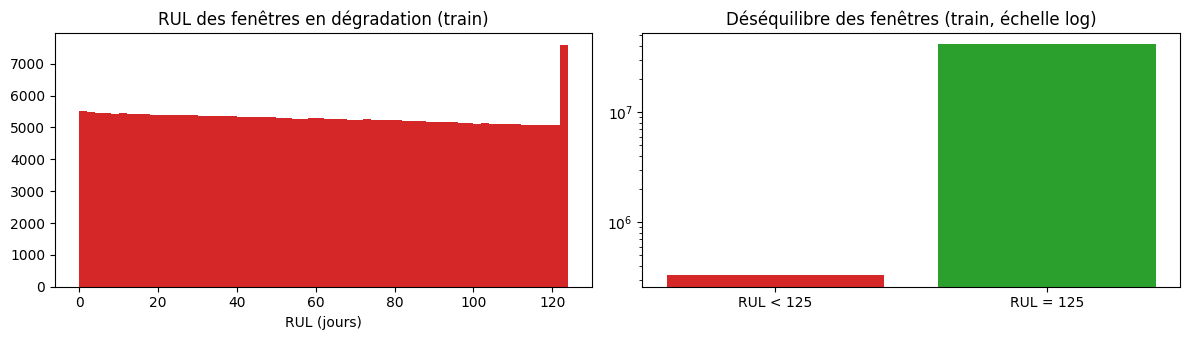

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(tr["rul"][tr["ends_low"]], bins=62, color="tab:red")
ax[0].set_title("RUL des fenêtres en dégradation (train)"); ax[0].set_xlabel("RUL (jours)")
counts = [len(tr["ends_low"]), len(tr["ends_high"])]
ax[1].bar(["RUL < 125", "RUL = 125"], counts, color=["tab:red", "tab:green"])
ax[1].set_yscale("log"); ax[1].set_title("Déséquilibre des fenêtres (train, échelle log)")
plt.tight_layout(); plt.show()

## 7. Données sur le GPU et extraction des fenêtres à la volée
Les séries (float16) sont copiées sur le GPU si elles tiennent dans 60 % de la VRAM. Une fenêtre est obtenue par simple indexation `X[fin-29 : fin+1]`, directement sur le GPU : pas de DataLoader, pas de copie CPU→GPU à chaque batch.

In [8]:
total_bytes = sum(d["X"].nbytes for d in (tr, va, te))
ON_GPU = device.type == "cuda" and total_bytes < 0.6 * torch.cuda.get_device_properties(0).total_memory
data_dev = device if ON_GPU else torch.device("cpu")
print(f"Séries : {total_bytes/1e9:.2f} Go -> stockées sur", data_dev)

for d in (tr, va, te):
    d["X_t"] = torch.from_numpy(d["X"]).to(data_dev)
    d["rul_t"] = torch.from_numpy(d["rul"]).to(data_dev)
    if ON_GPU:
        del d["X"]            # la copie RAM n'est plus utile
gc.collect()
OFFS = torch.arange(-C.WINDOW + 1, 1, device=data_dev)

def get_batch(d, ends_np):
    e = torch.from_numpy(np.ascontiguousarray(ends_np)).to(data_dev)
    xb = d["X_t"][e[:, None] + OFFS]               # (B, WINDOW, N_FEAT)
    yb = d["rul_t"][e] / C.RUL_CAP                 # cible normalisée dans [0, 1]
    return xb.to(device, non_blocking=True).float(), yb.to(device, non_blocking=True)

xb, yb = get_batch(tr, tr["ends_low"][:4])
print("Batch test :", tuple(xb.shape), tuple(yb.shape))
ram("données prêtes")

Séries : 2.92 Go -> stockées sur cuda
Batch test : (4, 30, 24) (4,)
[RAM] données prêtes               processus =  24.1 Go | dispo =  29.7 /  33.7 Go | VRAM =  3.2 Go


## 8. Architecture CNN-1D
Les filtres convolutifs glissent le long de l'axe temporel et apprennent des **motifs locaux de dégradation** (hausse brutale des secteurs réalloués, pics d'erreurs…). En sortie, on concatène un *global average pooling* (tendance moyenne) et un *global max pooling* (pics ponctuels, très informatifs pour les attributs S.M.A.R.T.).

In [9]:
class CNN1D(nn.Module):
    def __init__(self, n_feat, ch=(64, 64, 128), k=3, dropout=0.3):
        super().__init__()
        p = k // 2
        self.features = nn.Sequential(
            nn.Conv1d(n_feat, ch[0], k, padding=p), nn.BatchNorm1d(ch[0]), nn.ReLU(),
            nn.Conv1d(ch[0], ch[1], k, padding=p), nn.BatchNorm1d(ch[1]), nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(ch[1], ch[2], k, padding=p), nn.BatchNorm1d(ch[2]), nn.ReLU(),
        )
        self.head = nn.Sequential(
            nn.Linear(2 * ch[2], 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 1)
        )

    def forward(self, x):                      # x : (B, L, F)
        h = self.features(x.transpose(1, 2))   # Conv1d attend (B, F, L)
        h = torch.cat([h.mean(-1), h.amax(-1)], dim=1)
        return self.head(h).squeeze(-1)

model = CNN1D(N_FEAT, C.CHANNELS, C.KERNEL, C.DROPOUT).to(device)
print(model)
print(f"Paramètres entraînables : {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

CNN1D(
  (features): Sequential(
    (0): Conv1d(24, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (4): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (8): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU()
  )
  (head): Sequential(
    (0): Linear(in_features=256, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)
Paramètres entraînables : 58,753


## 9. Entraînement
- Perte **Huber** (robuste aux valeurs aberrantes des attributs S.M.A.R.T.), optimiseur AdamW, réduction du learning rate sur plateau
- **Précision mixte** (AMP) sur GPU : environ 2× plus rapide sur T4
- **Early stopping** sur le RMSE de validation, meilleur modèle sauvegardé à chaque amélioration
- Arrêt automatique après `MAX_TRAIN_MINUTES`

In [10]:
use_amp = device.type == "cuda"
try:
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
def autocast():
    return torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp)

opt = torch.optim.AdamW(model.parameters(), lr=C.LR, weight_decay=C.WEIGHT_DECAY)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=2)
loss_fn = nn.HuberLoss(delta=0.1)   # delta = 0,1 x 125 ≈ 12 jours
CKPT = os.path.join(C.OUT_DIR, "cnn1d_best.pt")

@torch.no_grad()
def predict(d, ends, bs=C.EVAL_BATCH):
    model.eval()
    out = np.empty(len(ends), dtype=np.float32)
    for i in range(0, len(ends), bs):
        xb, _ = get_batch(d, ends[i:i + bs])
        with autocast():
            p = model(xb)
        out[i:i + bs] = (p.float().clamp(0, 1) * C.RUL_CAP).cpu().numpy()
    return out

def rmse(y, p): return float(np.sqrt(np.mean((p - y) ** 2))) if len(y) else float("nan")

rng = np.random.default_rng(C.SEED)
yv_s = va["rul"][val_ends_s]
history, best, bad, t0 = [], float("inf"), 0, time.time()

for ep in range(1, C.EPOCHS + 1):
    te0 = time.time()
    model.train()
    ends = sample_ends(tr["ends_low"], tr["ends_high"], C.HEALTHY_RATIO, rng)
    run_loss, nb = 0.0, 0
    for i in range(0, len(ends), C.BATCH_SIZE):
        xb, yb = get_batch(tr, ends[i:i + C.BATCH_SIZE])
        opt.zero_grad(set_to_none=True)
        with autocast():
            out = model(xb)
        loss = loss_fn(out.float(), yb)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update()
        run_loss += loss.item(); nb += 1

    pv = predict(va, val_ends_s)
    low = yv_s < C.RUL_CAP
    v_rmse, v_low, v_high = rmse(yv_s, pv), rmse(yv_s[low], pv[low]), rmse(yv_s[~low], pv[~low])
    crit = 0.5 * (v_low + v_high)          # V2 : critère du protocole commun
    sched.step(crit)
    history.append(dict(epoch=ep, train_loss=run_loss / nb, val_rmse=v_rmse, val_rmse_low=v_low,
                        val_rmse_high=v_high, crit=crit, lr=opt.param_groups[0]["lr"]))
    flag = ""
    if crit < best - 1e-3:
        best, bad, flag = crit, 0, "  <- meilleur, sauvegardé"
        torch.save(model.state_dict(), CKPT)
    else:
        bad += 1
    elapsed = (time.time() - t0) / 60
    print(f"Epoch {ep:02d} | loss {run_loss/nb:.4f} | RMSE dégr. {v_low:6.2f} j | "
          f"RMSE sain {v_high:6.2f} j | critère {crit:6.2f} | lr {opt.param_groups[0]['lr']:.1e} | "
          f"{time.time()-te0:.0f} s{flag}")
    if bad >= C.PATIENCE:
        print("Early stopping."); break
    if elapsed > C.MAX_TRAIN_MINUTES:
        print("Limite de temps atteinte : arrêt propre."); break

TRAIN_MIN = (time.time() - t0) / 60
model.load_state_dict(torch.load(CKPT, map_location=device))
print(f"\nMeilleur critère : {best:.2f} jours | durée totale : {TRAIN_MIN:.1f} min")
ram("après entraînement")

Epoch 01 | loss 0.0159 | RMSE dégr.  45.76 j | RMSE sain  27.12 j | critère  36.44 | lr 1.0e-03 | 11 s  <- meilleur, sauvegardé
Epoch 02 | loss 0.0129 | RMSE dégr.  56.06 j | RMSE sain  10.46 j | critère  33.26 | lr 1.0e-03 | 5 s  <- meilleur, sauvegardé
Epoch 03 | loss 0.0122 | RMSE dégr.  60.15 j | RMSE sain   6.93 j | critère  33.54 | lr 1.0e-03 | 5 s
Epoch 04 | loss 0.0120 | RMSE dégr.  41.29 j | RMSE sain  47.56 j | critère  44.43 | lr 1.0e-03 | 5 s
Epoch 05 | loss 0.0119 | RMSE dégr.  52.93 j | RMSE sain  13.74 j | critère  33.34 | lr 5.0e-04 | 5 s
Epoch 06 | loss 0.0117 | RMSE dégr.  49.86 j | RMSE sain  22.69 j | critère  36.28 | lr 5.0e-04 | 5 s
Epoch 07 | loss 0.0116 | RMSE dégr.  43.59 j | RMSE sain  47.99 j | critère  45.79 | lr 5.0e-04 | 5 s
Early stopping.

Meilleur critère : 33.26 jours | durée totale : 0.7 min
[RAM] après entraînement           processus =  25.1 Go | dispo =  28.9 /  33.7 Go | VRAM =  3.2 Go


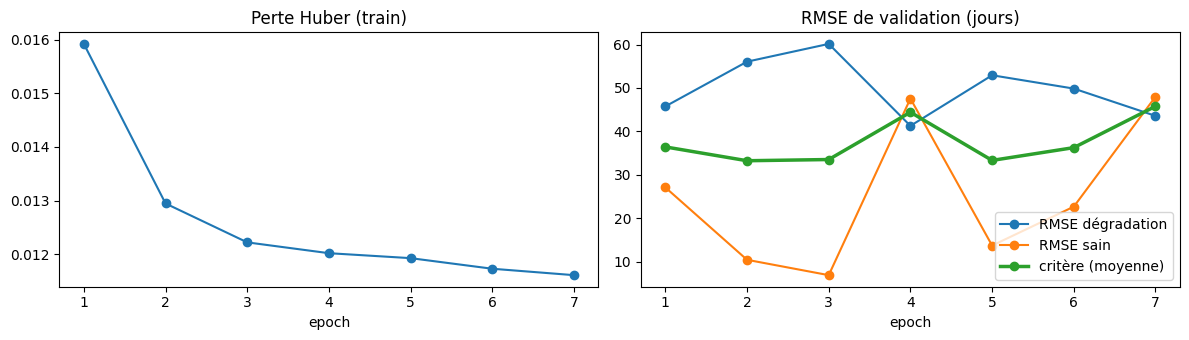

In [11]:
h = pl.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(h["epoch"], h["train_loss"], marker="o"); ax[0].set_title("Perte Huber (train)")
ax[1].plot(h["epoch"], h["val_rmse_low"], marker="o", label="RMSE dégradation")
ax[1].plot(h["epoch"], h["val_rmse_high"], marker="o", label="RMSE sain")
ax[1].plot(h["epoch"], h["crit"], marker="o", lw=2.5, label="critère (moyenne)")
ax[1].set_title("RMSE de validation (jours)"); ax[1].legend()
for a in ax: a.set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 10. Choix du seuil d'alerte (validation complète)
Une alerte « panne imminente » est levée si **RUL prédite ≤ seuil**. Le seuil est choisi pour maximiser le F1 sur **toute** la validation, avec la vraie proportion de pannes. Le test n'est jamais utilisé pour ce choix (pas de fuite).

In [12]:
pv_all = predict(va, va["ends_all"])
yv_all = va["rul"][va["ends_all"]]
yv_alert = (yv_all <= C.ALERT_HORIZON).astype(np.int8)

prec, rec, thr = precision_recall_curve(yv_alert, -pv_all)   # score = -RUL prédite
f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
best_i = int(np.nanargmax(f1))
THRESH = float(-thr[best_i])
print(f"Seuil retenu : RUL prédite <= {THRESH:.1f} jours")
print(f"Validation -> précision {prec[best_i]:.3f} | rappel {rec[best_i]:.3f} | F1 {f1[best_i]:.3f}")

Seuil retenu : RUL prédite <= 59.8 jours
Validation -> précision 0.174 | rappel 0.155 | F1 0.164


## 11. Évaluation sur le test complet
Trois niveaux d'analyse :
1. **Régression RUL** : RMSE / MAE globaux (dominés par les disques sains), puis sur les fenêtres en dégradation (**métrique principale**), par tranche de RUL, et score asymétrique NASA (une RUL surestimée, donc une alerte tardive, est plus pénalisée qu'une RUL sous-estimée).
2. **Alerte par fenêtre** : précision, rappel, F1, matrice de confusion, précision moyenne (AP).
3. **Alerte par disque** (vision métier) : part des disques défaillants détectés à temps, avance moyenne de l'alerte, part des disques sains ayant déclenché une fausse alerte.

In [13]:
pt = predict(te, te["ends_all"])
yt = te["rul"][te["ends_all"]]
seg_t = te["seg"][te["ends_all"]]

def nasa_score(y, p):
    d = p - y
    return float(np.mean(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

def reg(y, p):
    return dict(n=int(len(y)), RMSE=rmse(y, p),
                MAE=float(np.mean(np.abs(p - y))) if len(y) else float("nan"))

low = yt < C.RUL_CAP
results = {"regression": {
    "global (vraie distribution)": reg(yt, pt),
    "degradation (RUL<125)": reg(yt[low], pt[low]),
    f"imminent (RUL<={C.ALERT_HORIZON})": reg(yt[yt <= C.ALERT_HORIZON], pt[yt <= C.ALERT_HORIZON]),
    "baseline 'toujours 125' (RUL<125)": reg(yt[low], np.full(low.sum(), C.RUL_CAP, np.float32)),
}}
results["regression"]["degradation (RUL<125)"]["score_NASA_moyen"] = nasa_score(yt[low], pt[low])

bins = [(0, 10), (10, 30), (30, 60), (60, 125), (125, 126)]
results["par_tranche"] = {f"[{a},{b})" if b <= C.RUL_CAP else "125 (sain)":
                          reg(yt[(yt >= a) & (yt < b)], pt[(yt >= a) & (yt < b)]) for a, b in bins}

y_alert = (yt <= C.ALERT_HORIZON).astype(np.int8)
p_alert = (pt <= THRESH).astype(np.int8)
cm = confusion_matrix(y_alert, p_alert, labels=[0, 1])
results["alerte_fenetre"] = dict(
    seuil=THRESH, precision=float(precision_score(y_alert, p_alert, zero_division=0)),
    rappel=float(recall_score(y_alert, p_alert, zero_division=0)),
    F1=float(f1_score(y_alert, p_alert, zero_division=0)),
    AP=float(average_precision_score(y_alert, -pt)),
    matrice_confusion=cm.tolist())

# V2 : niveau disque par numéro de série (protocole commun)
disk_names, seg2disk = np.unique(np.array(te["seg_serial"]), return_inverse=True)
disk_t = seg2disk[seg_t]
n_disk = len(disk_names)
failing = np.bincount(disk_t, weights=(yt < C.RUL_CAP), minlength=n_disk) > 0
has_win = np.bincount(disk_t, minlength=n_disk) > 0
alarm_imm = np.bincount(disk_t, weights=(p_alert & y_alert), minlength=n_disk) > 0
alarm_any = np.bincount(disk_t, weights=p_alert, minlength=n_disk) > 0
first_alarm_rul = np.full(n_disk, -1.0)
m = (p_alert == 1) & (yt < C.RUL_CAP)
np.maximum.at(first_alarm_rul, disk_t[m], yt[m])    # RUL réelle à la 1re alerte
healthy = has_win & ~failing
detected = failing & alarm_imm
results["alerte_disque"] = dict(
    disques_defaillants=int(failing.sum()),
    detectes_avant_panne=int(detected.sum()),
    taux_detection=float(detected.sum() / max(failing.sum(), 1)),
    avance_moyenne_jours=float(first_alarm_rul[detected].mean()) if detected.any() else None,
    disques_sains=int(healthy.sum()),
    taux_fausse_alerte_disques_sains=float((alarm_any & healthy).sum() / max(healthy.sum(), 1)),
)

print(json.dumps(results, indent=2, ensure_ascii=False))

{
  "regression": {
    "global (vraie distribution)": {
      "n": 8969549,
      "RMSE": 11.516357421875,
      "MAE": 6.576149940490723
    },
    "degradation (RUL<125)": {
      "n": 67457,
      "RMSE": 56.826995849609375,
      "MAE": 46.702728271484375,
      "score_NASA_moyen": 6848.64501953125
    },
    "imminent (RUL<=30)": {
      "n": 17361,
      "RMSE": 84.00033569335938,
      "MAE": 78.25701904296875
    },
    "baseline 'toujours 125' (RUL<125)": {
      "n": 67457,
      "RMSE": 73.51731872558594,
      "MAE": 64.0667953491211
    }
  },
  "par_tranche": {
    "[0,10)": {
      "n": 5633,
      "RMSE": 89.52978515625,
      "MAE": 83.3817367553711
    },
    "[10,30)": {
      "n": 11175,
      "RMSE": 81.5687026977539,
      "MAE": 76.15473175048828
    },
    "[30,60)": {
      "n": 16461,
      "RMSE": 62.051082611083984,
      "MAE": 56.33928680419922
    },
    "[60,125)": {
      "n": 34188,
      "RMSE": 31.975479125976562,
      "MAE": 26.392494201660156
   

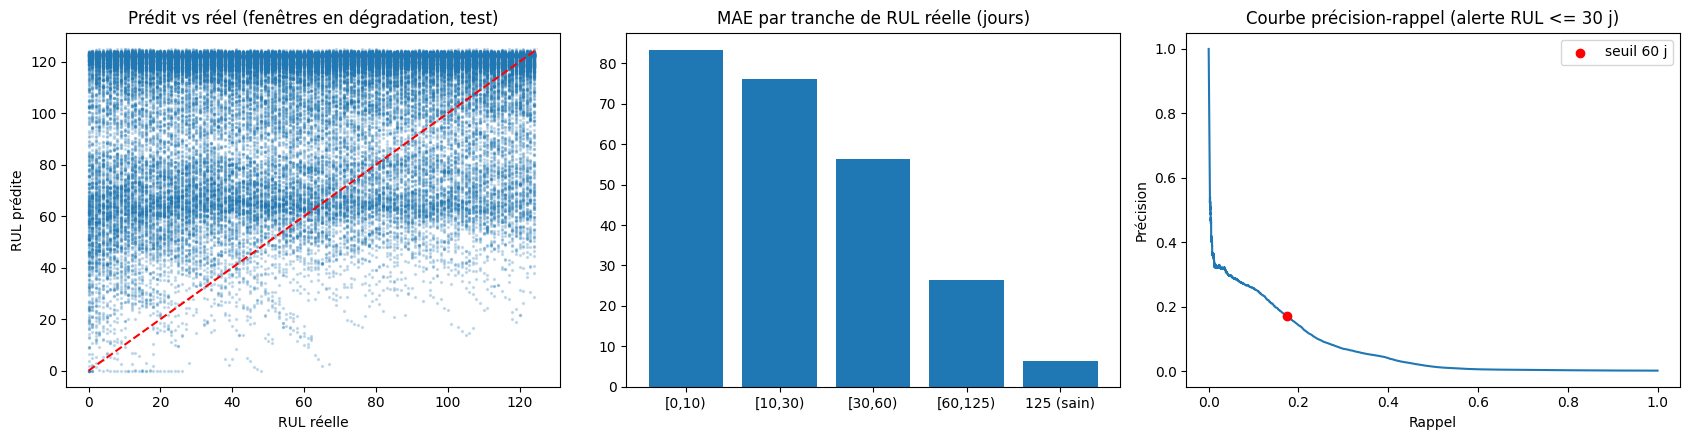

Matrice de confusion (lignes = réel, colonnes = prédit) [sain, imminent] :
[[8937421   14767]
 [  14336    3025]]


In [14]:
rng_plot = np.random.default_rng(0)
idx_low = np.flatnonzero(low)
sel = rng_plot.choice(idx_low, min(50_000, len(idx_low)), replace=False)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(yt[sel], pt[sel], s=2, alpha=0.2)
ax[0].plot([0, C.RUL_CAP], [0, C.RUL_CAP], "r--")
ax[0].set_xlabel("RUL réelle"); ax[0].set_ylabel("RUL prédite")
ax[0].set_title("Prédit vs réel (fenêtres en dégradation, test)")

tr_names = list(results["par_tranche"].keys())
ax[1].bar(tr_names, [results["par_tranche"][k]["MAE"] for k in tr_names])
ax[1].set_title("MAE par tranche de RUL réelle (jours)")

p_te, r_te, _ = precision_recall_curve(y_alert, -pt)
ax[2].plot(r_te, p_te)
ax[2].scatter([results["alerte_fenetre"]["rappel"]], [results["alerte_fenetre"]["precision"]],
              color="red", zorder=3, label=f"seuil {THRESH:.0f} j")
ax[2].set_xlabel("Rappel"); ax[2].set_ylabel("Précision"); ax[2].legend()
ax[2].set_title(f"Courbe précision-rappel (alerte RUL <= {C.ALERT_HORIZON} j)")
plt.tight_layout(); plt.show()

print("Matrice de confusion (lignes = réel, colonnes = prédit) [sain, imminent] :")
print(cm)

### Suivi de quelques disques défaillants du test

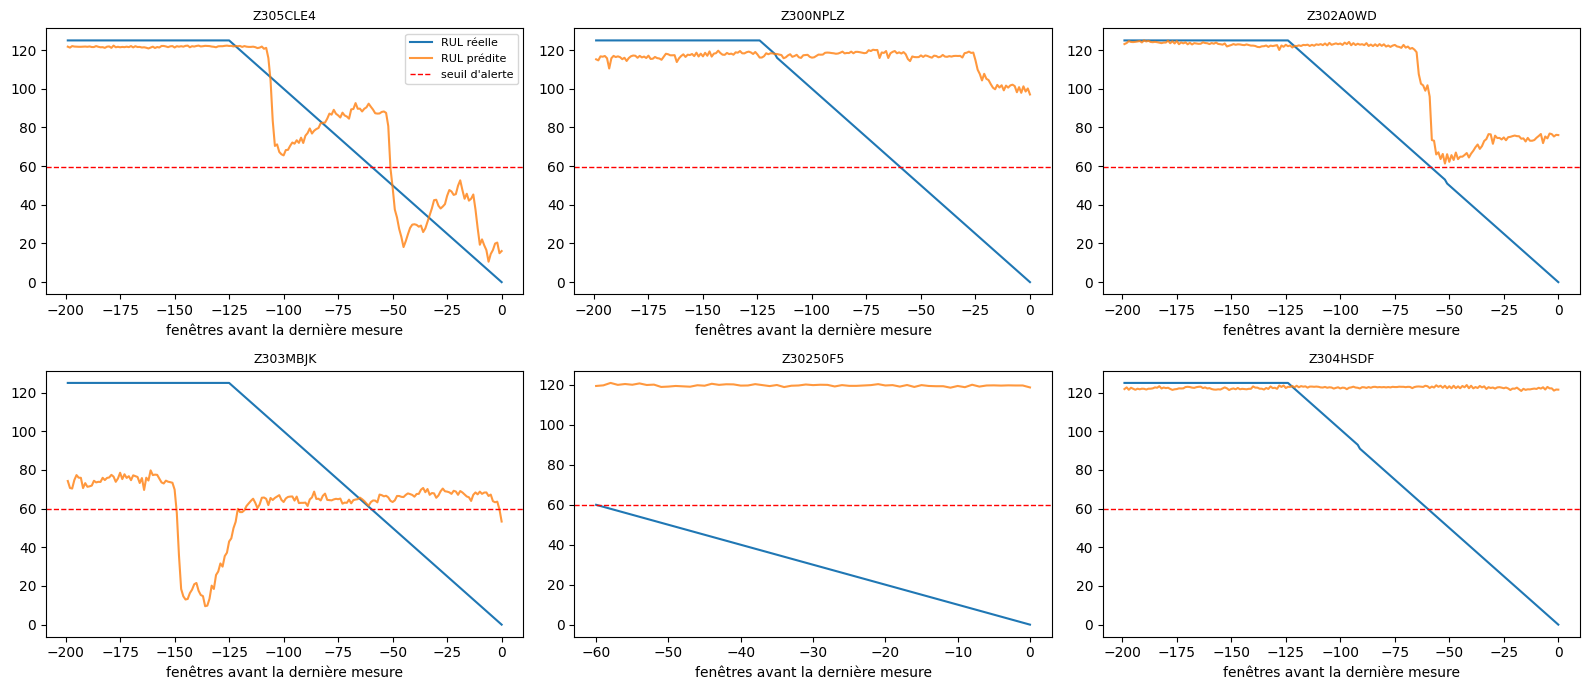

In [15]:
fail_ids = np.flatnonzero(failing)
show = rng_plot.choice(fail_ids, min(6, len(fail_ids)), replace=False)
fig, axes = plt.subplots(2, 3, figsize=(16, 7)); axes = axes.ravel()
for a, s in zip(axes, show):
    mk = disk_t == s
    yy, pp = yt[mk][-200:], pt[mk][-200:]
    x = np.arange(-len(yy) + 1, 1)
    a.plot(x, yy, label="RUL réelle"); a.plot(x, pp, label="RUL prédite", alpha=0.8)
    a.axhline(THRESH, color="red", ls="--", lw=1, label="seuil d'alerte")
    a.set_title(disk_names[s], fontsize=9); a.set_xlabel("fenêtres avant la dernière mesure")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 12. Sauvegarde des résultats (pour la comparaison avec les autres modèles du groupe)
Le fichier `predictions_test_cnn1d.parquet` contient, pour chaque fenêtre du test, le disque, la date de fin de fenêtre, la RUL réelle et la RUL prédite. Si les autres modèles (Random Forest, LSTM, GRU) utilisent la même fenêtre de 30 jours et le même split, une simple jointure sur `(serial_number, date)` permet de les comparer sur exactement les mêmes exemples.

In [16]:
# V2 : format du protocole commun (val + test)
def save_preds(d, ends, pred, path):
    seg_tab = pl.DataFrame({"seg": np.arange(len(d["seg_serial"]), dtype=np.int32),
                            "serial_number": d["seg_serial"]})
    (pl.DataFrame({"seg": d["seg"][ends], "date": d["date"][ends],
                   "rul_true": d["rul"][ends], "rul_pred": pred.astype(np.float32)})
       .with_columns(pl.col("date").cast(pl.Date))
       .join(seg_tab, on="seg", how="left")
       .select(["serial_number", "date", "rul_true", "rul_pred"])
       .write_parquet(path))
    print(f"{os.path.basename(path)} : {len(ends):,} lignes")

save_preds(va, va["ends_all"], pv_all, os.path.join(C.OUT_DIR, "predictions_val_cnn1d.parquet"))
save_preds(te, te["ends_all"], pt, os.path.join(C.OUT_DIR, "predictions_test_cnn1d.parquet"))

cfg = {k: v for k, v in vars(C).items()}
cfg.update(FEATURES=FEATURES, version="v2",
           n_parametres=sum(p.numel() for p in model.parameters()),
           epochs_effectues=len(history), temps_entrainement_min=round(TRAIN_MIN, 2),
           meilleur_critere_val=best, seuil_alerte=THRESH,
           gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")
with open(os.path.join(C.OUT_DIR, "config_cnn1d.json"), "w") as f:
    json.dump(cfg, f, indent=2, ensure_ascii=False, default=str)
with open(os.path.join(C.OUT_DIR, "metrics_test_cnn1d.json"), "w") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)
pl.DataFrame(history).write_csv(os.path.join(C.OUT_DIR, "history_cnn1d.csv"))
print("Fichiers sauvegardés :", os.listdir(C.OUT_DIR))
ram("fin")

predictions_val_cnn1d.parquet : 8,933,738 lignes
predictions_test_cnn1d.parquet : 8,969,549 lignes
Fichiers sauvegardés : ['metrics_test_cnn1d.json', 'history_cnn1d.csv', 'predictions_val_cnn1d.parquet', 'cnn1d_best.pt', 'config_cnn1d.json', 'predictions_test_cnn1d.parquet']
[RAM] fin                          processus =  25.5 Go | dispo =  28.6 /  33.7 Go | VRAM =  3.2 Go


## 13. Analyse des résultats (à compléter pour le rapport)
- **Le modèle apprend-il vraiment ?** Comparer le RMSE sur les fenêtres en dégradation à la baseline « toujours 125 ». Seul un écart net montre que le CNN détecte la dégradation.
- **Où se trompe-t-il ?** MAE par tranche : une erreur faible près de la panne (RUL < 30) compte plus que sur les disques sains.
- **Alerte :** sur la vraie distribution, les fenêtres « imminentes » sont très rares, donc une précision par fenêtre modeste est attendue. Les indicateurs par disque (taux de détection, avance de l'alerte, fausses alertes) sont les plus parlants pour un exploitant de data center.
- **Pistes d'amélioration à tester** (et à consigner dans un tableau d'expériences) : `WINDOW` (14 / 30 / 60), `HEALTHY_RATIO` (1 / 2 / 5), `CHANNELS`, `KERNEL` (3 / 5 / 7), `DROPOUT`, `ALERT_HORIZON`.